In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import warnings
warnings.filterwarnings("ignore")

C:\Users\chman\AppData\Roaming\Python\Python311\site-packages\pandas\core\arrays\masked.py:61: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [2]:
folder = r"C:\dataset\Alibaba_MS_Trace_2022_FINAL_FOR_PAPER"

autoscaling_df = pd.read_csv(folder + r"\autoscaling_trace_dataset.csv")
graph_df = pd.read_csv(folder + r"\service_graph_edges_sample.csv")

print("Autoscaling dataset shape:", autoscaling_df.shape)
print("Graph dataset shape:", graph_df.shape)

display(autoscaling_df.head())
display(graph_df.head())

Autoscaling dataset shape: (1907, 17)
Graph dataset shape: (299999, 5)


,time_step,timestamp,service_id,cpu_utilization,memory_utilization,request_rate,latency_ms,queue_length,replica_count,cost,sla_violation,load_pressure,gmm_cluster,gmm_prob_0,gmm_prob_1,gmm_prob_2,workload_regime
0,0,0.0,MS_10918,0.086625,0.706766,0.000010,18.089460,0.0,1,1.0,0,0.264467,2,6.025774e-07,1.016178e-02,9.898376e-01,low_load
1,0,0.0,MS_11461,0.378720,0.817383,0.001208,4.290294,0.0,14,14.0,0,0.399103,1,1.393340e-05,9.999861e-01,6.931376e-122,high_load
2,0,0.0,MS_11642,0.145500,0.625041,0.000702,1.179563,0.0,7,7.0,0,0.257081,1,4.559718e-05,9.999544e-01,1.128856e-41,high_load
3,0,0.0,MS_11681,0.104792,0.703653,0.000014,73.017248,0.0,2,2.0,0,0.269486,2,1.122958e-05,1.782322e-07,9.999886e-01,low_load
4,0,0.0,MS_11903,0.154965,0.890620,0.000267,34.281866,0.0,25,25.0,0,0.348617,1,1.768260e-04,9.858336e-01,1.398954e-02,high_load


,timestamp,source_service,rpc_type,destination_service,edge_latency_ms
0,115352.0,rpc,MS_58845_POD_0,MS_71712,2.0
1,86450.0,rpc,MS_24094_POD_3317,MS_24094,5.0
2,86450.0,rpc,MS_24094_POD_983,MS_24094,5.0
3,155753.0,rpc,MS_24094_POD_5463,MS_67455,9.0
4,90649.0,http,MS_29868_POD_22,UNKNOWN,18.0


In [43]:
autoscaling_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1907 entries, 0 to 1906
Data columns (total 17 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   time_step           1907 non-null   int64  
 1   timestamp           1907 non-null   float64
 2   service_id          1907 non-null   object 
 3   cpu_utilization     1907 non-null   float64
 4   memory_utilization  1907 non-null   float64
 5   request_rate        1907 non-null   float64
 6   latency_ms          1907 non-null   float64
 7   queue_length        1907 non-null   float64
 8   replica_count       1907 non-null   int64  
 9   cost                1907 non-null   float64
 10  sla_violation       1907 non-null   int64  
 11  load_pressure       1907 non-null   float64
 12  gmm_cluster         1907 non-null   int64  
 13  gmm_prob_0          1907 non-null   float64
 14  gmm_prob_1          1907 non-null   float64
 15  gmm_prob_2          1907 non-null   float64
 16  worklo

In [3]:
autoscaling_df.describe()

,time_step,timestamp,cpu_utilization,memory_utilization,request_rate,latency_ms,queue_length,replica_count,cost,sla_violation,load_pressure,gmm_cluster,gmm_prob_0,gmm_prob_1,gmm_prob_2
count,1907.000000,1907.000000,1907.000000,1907.000000,1907.000000,1907.000000,1907.0,1907.000000,1907.000000,1907.000000,1907.000000,1907.000000,1.907000e+03,1907.000000,1.907000e+03
mean,2.766125,165967.488201,0.152221,0.603219,0.000292,220.376654,0.0,5.795490,5.795490,0.057158,0.251911,1.580493,4.282789e-02,0.346922,6.102497e-01
std,1.679718,100783.108897,0.124385,0.170764,0.000722,6958.011470,0.0,7.351833,7.351833,0.232205,0.080898,0.574189,1.999273e-01,0.448091,4.603944e-01
min,0.000000,0.000000,0.003285,0.049503,0.000000,0.000000,0.0,1.000000,1.000000,0.000000,0.020671,0.000000,1.568217e-12,0.000000,0.000000e+00
25%,1.000000,60000.000000,0.069476,0.502245,0.000009,3.009567,0.0,1.000000,1.000000,0.000000,0.202249,1.000000,1.074389e-06,0.004904,2.793403e-07
50%,3.000000,180000.000000,0.113578,0.633211,0.000055,7.219953,0.0,3.000000,3.000000,0.000000,0.254712,2.000000,4.027309e-06,0.023196,9.657754e-01
75%,4.000000,240000.000000,0.192766,0.714596,0.000255,18.783459,0.0,7.000000,7.000000,0.000000,0.303298,2.000000,2.787586e-05,0.998457,9.928547e-01
max,5.000000,300000.000000,0.969521,0.970619,0.011456,301636.853659,0.0,47.000000,47.000000,1.000000,0.590548,2.000000,1.000000e+00,1.000000,9.999963e-01


In [45]:
autoscaling_df["workload_regime"].value_counts()

workload_regime
low_load       1189
high_load       636
medium_load      82
Name: count, dtype: int64

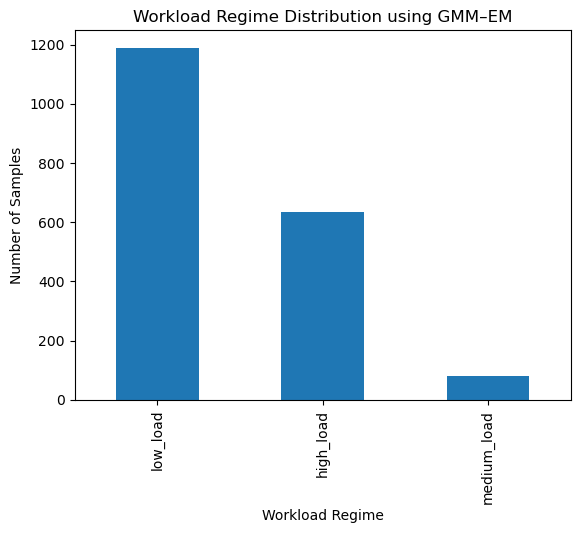

In [4]:
autoscaling_df["workload_regime"].value_counts().plot(kind="bar")
plt.title("Workload Regime Distribution using GMM–EM")
plt.xlabel("Workload Regime")
plt.ylabel("Number of Samples")
plt.show()

In [5]:
# Remove unknown or missing destination services
graph_clean = graph_df.copy()

graph_clean = graph_clean[
    (graph_clean["source_service"].notna()) &
    (graph_clean["destination_service"].notna()) &
    (graph_clean["destination_service"] != "UNKNOWN")
]

graph_clean.head()

,timestamp,source_service,rpc_type,destination_service,edge_latency_ms
0,115352.0,rpc,MS_58845_POD_0,MS_71712,2.0
1,86450.0,rpc,MS_24094_POD_3317,MS_24094,5.0
2,86450.0,rpc,MS_24094_POD_983,MS_24094,5.0
3,155753.0,rpc,MS_24094_POD_5463,MS_67455,9.0
5,90664.0,rpc,MS_51514_POD_3,MS_10343,0.0


In [6]:
out_degree = (
    graph_clean
    .groupby("source_service")["destination_service"]
    .nunique()
    .reset_index()
    .rename(columns={
        "source_service": "service_id",
        "destination_service": "out_degree"
    })
)

out_degree.head()

,service_id,out_degree
0,0.1.1.1,2
1,0.1.1.1.1,2
2,0.1.1.1.2,1
3,0.1.1.1.3,1
4,0.1.1.2,1


In [7]:
in_degree = (
    graph_clean
    .groupby("destination_service")["source_service"]
    .nunique()
    .reset_index()
    .rename(columns={
        "destination_service": "service_id",
        "source_service": "in_degree"
    })
)

in_degree.head()

,service_id,in_degree
0,7zAD1u2Ce4,2
1,KWJVXNzrUs,1
2,MS_10041,1
3,MS_10054,1
4,MS_10099,1


In [8]:
edge_latency = (
    graph_clean
    .groupby("source_service")["edge_latency_ms"]
    .mean()
    .reset_index()
    .rename(columns={
        "source_service": "service_id",
        "edge_latency_ms": "avg_edge_latency"
    })
)

edge_latency.head()

,service_id,avg_edge_latency
0,0.1.1.1,NaN
1,0.1.1.1.1,NaN
2,0.1.1.1.2,NaN
3,0.1.1.1.3,NaN
4,0.1.1.2,NaN


In [9]:
graph_features = out_degree.merge(in_degree, on="service_id", how="outer")
graph_features = graph_features.merge(edge_latency, on="service_id", how="outer")

graph_features.fillna(0, inplace=True)

display(graph_features.head())

,service_id,out_degree,in_degree,avg_edge_latency
0,0.1.1.1,2.0,0.0,0.0
1,0.1.1.1.1,2.0,0.0,0.0
2,0.1.1.1.2,1.0,0.0,0.0
3,0.1.1.1.3,1.0,0.0,0.0
4,0.1.1.2,1.0,0.0,0.0


In [10]:
data = autoscaling_df.merge(graph_features, on="service_id", how="left")

data[["out_degree", "in_degree", "avg_edge_latency"]] = data[
    ["out_degree", "in_degree", "avg_edge_latency"]
].fillna(0)

print("Final merged dataset shape:", data.shape)
display(data.head())

Final merged dataset shape: (1907, 20)


,time_step,timestamp,service_id,cpu_utilization,memory_utilization,request_rate,latency_ms,queue_length,replica_count,cost,sla_violation,load_pressure,gmm_cluster,gmm_prob_0,gmm_prob_1,gmm_prob_2,workload_regime,out_degree,in_degree,avg_edge_latency
0,0,0.0,MS_10918,0.086625,0.706766,0.000010,18.089460,0.0,1,1.0,0,0.264467,2,6.025774e-07,1.016178e-02,9.898376e-01,low_load,0.0,0.0,0.0
1,0,0.0,MS_11461,0.378720,0.817383,0.001208,4.290294,0.0,14,14.0,0,0.399103,1,1.393340e-05,9.999861e-01,6.931376e-122,high_load,0.0,0.0,0.0
2,0,0.0,MS_11642,0.145500,0.625041,0.000702,1.179563,0.0,7,7.0,0,0.257081,1,4.559718e-05,9.999544e-01,1.128856e-41,high_load,0.0,0.0,0.0
3,0,0.0,MS_11681,0.104792,0.703653,0.000014,73.017248,0.0,2,2.0,0,0.269486,2,1.122958e-05,1.782322e-07,9.999886e-01,low_load,0.0,0.0,0.0
4,0,0.0,MS_11903,0.154965,0.890620,0.000267,34.281866,0.0,25,25.0,0,0.348617,1,1.768260e-04,9.858336e-01,1.398954e-02,high_load,0.0,0.0,0.0


In [12]:
baseline_features = [
    "cpu_utilization",
    "memory_utilization",
    "request_rate",
    "latency_ms",
    "queue_length",
    "replica_count"
]

proposed_features = [
    "cpu_utilization",
    "memory_utilization",
    "request_rate",
    "latency_ms",
    "queue_length",
    "replica_count",
    "gmm_prob_0",
    "gmm_prob_1",
    "gmm_prob_2",
    "out_degree",
    "in_degree",
    "avg_edge_latency"
]

In [13]:
evaluation_columns = [
    "latency_ms",
    "cost",
    "sla_violation"
]

In [14]:
data = data.sort_values("time_step").reset_index(drop=True)

split_index = int(len(data) * 0.8)

train_data = data.iloc[:split_index].copy()
test_data = data.iloc[split_index:].copy()

print("Train shape:", train_data.shape)
print("Test shape:", test_data.shape)

Train shape: (1525, 20)
Test shape: (382, 20)


In [15]:
class AutoscalingEnvironment:
    def __init__(self, df, feature_columns, max_replicas=6, sla_threshold=85):
        self.df = df.reset_index(drop=True)
        self.feature_columns = feature_columns
        self.max_replicas = max_replicas
        self.sla_threshold = sla_threshold
        self.index = 0

    def reset(self):
        self.index = 0
        return self._get_state()

    def _get_state(self):
        row = self.df.iloc[self.index]
        return row[self.feature_columns].values.astype(np.float32)

    def step(self, action):
        row = self.df.iloc[self.index]

        current_replicas = int(max(1, row["replica_count"]))

        if action == 0:
            new_replicas = max(1, current_replicas - 1)
        elif action == 1:
            new_replicas = current_replicas
        else:
            new_replicas = min(self.max_replicas, current_replicas + 1)

        # Approximate latency effect of scaling
        old_latency = row["latency_ms"]
        old_replicas = max(1, current_replicas)

        estimated_latency = old_latency * (old_replicas / new_replicas)

        # Cost model
        estimated_cost = new_replicas * 1.0

        # SLA violation
        sla_violation = 1 if estimated_latency > self.sla_threshold else 0

        # Reward function: lower latency, lower cost, lower SLA violation
        reward = -(
            0.4 * (estimated_latency / self.sla_threshold)
            + 0.4 * (estimated_cost / self.max_replicas)
            + 0.2 * sla_violation
        )

        self.index += 1
        done = self.index >= len(self.df) - 1

        next_state = self._get_state() if not done else np.zeros(len(self.feature_columns))

        info = {
            "new_replicas": new_replicas,
            "estimated_latency": estimated_latency,
            "estimated_cost": estimated_cost,
            "sla_violation": sla_violation
        }

        return next_state, reward, done, info

In [16]:
env = AutoscalingEnvironment(train_data, proposed_features)

state = env.reset()
print("Initial state:", state)

next_state, reward, done, info = env.step(action=2)

print("Reward:", reward)
print("Info:", info)

Initial state: [8.6625002e-02 7.0676643e-01 1.0026845e-05 1.8089460e+01 0.0000000e+00
 1.0000000e+00 6.0257736e-07 1.0161780e-02 9.8983765e-01 0.0000000e+00
 0.0000000e+00 0.0000000e+00]
Reward: -0.17589676885899794
Info: {'new_replicas': 2, 'estimated_latency': 9.04473004920373, 'estimated_cost': 2.0, 'sla_violation': 0}


In [17]:
baseline_train_env = AutoscalingEnvironment(train_data, baseline_features)
baseline_test_env = AutoscalingEnvironment(test_data, baseline_features)

proposed_train_env = AutoscalingEnvironment(train_data, proposed_features)
proposed_test_env = AutoscalingEnvironment(test_data, proposed_features)

In [18]:
#Before DQN, create a simple autoscaling rule:
def rule_based_policy(row):
    if row["cpu_utilization"] > 0.70 or row["latency_ms"] > 85:
        return 2   # scale up
    elif row["cpu_utilization"] < 0.30 and row["latency_ms"] < 50:
        return 0   # scale down
    else:
        return 1   # no change

In [19]:
def evaluate_rule_policy(df, feature_columns):
    env = AutoscalingEnvironment(df, feature_columns)
    state = env.reset()

    rewards = []
    latencies = []
    costs = []
    sla_violations = []
    actions = []

    done = False

    while not done:
        row = env.df.iloc[env.index]
        action = rule_based_policy(row)

        next_state, reward, done, info = env.step(action)

        rewards.append(reward)
        latencies.append(info["estimated_latency"])
        costs.append(info["estimated_cost"])
        sla_violations.append(info["sla_violation"])
        actions.append(action)

    return {
        "avg_reward": np.mean(rewards),
        "avg_latency": np.mean(latencies),
        "avg_cost": np.mean(costs),
        "sla_violation_rate": np.mean(sla_violations),
        "scale_down": actions.count(0),
        "no_change": actions.count(1),
        "scale_up": actions.count(2)
    }

rule_results = evaluate_rule_policy(test_data, baseline_features)
rule_results

{'avg_reward': -0.7578181192076678,
 'avg_latency': 86.96810886181312,
 'avg_cost': 5.086614173228346,
 'sla_violation_rate': 0.047244094488188976,
 'scale_down': 296,
 'no_change': 57,
 'scale_up': 28}

In [20]:
#Before implementing full DQN, you can show the effect of GMM + graph features using policy logic.propose policy
def proposed_gmm_graph_policy(row):
    high_prob = row["gmm_prob_2"]
    low_prob = row["gmm_prob_0"]

    if high_prob > 0.60 or row["latency_ms"] > 85:
        return 2   # scale up
    elif low_prob > 0.60 and row["cpu_utilization"] < 0.50:
        return 0   # scale down
    else:
        return 1   # no change



In [21]:
def evaluate_proposed_policy(df, feature_columns):
    env = AutoscalingEnvironment(df, feature_columns)
    state = env.reset()

    rewards = []
    latencies = []
    costs = []
    sla_violations = []
    actions = []

    done = False

    while not done:
        row = env.df.iloc[env.index]
        action = proposed_gmm_graph_policy(row)

        next_state, reward, done, info = env.step(action)

        rewards.append(reward)
        latencies.append(info["estimated_latency"])
        costs.append(info["estimated_cost"])
        sla_violations.append(info["sla_violation"])
        actions.append(action)

    return {
        "avg_reward": np.mean(rewards),
        "avg_latency": np.mean(latencies),
        "avg_cost": np.mean(costs),
        "sla_violation_rate": np.mean(sla_violations),
        "scale_down": actions.count(0),
        "no_change": actions.count(1),
        "scale_up": actions.count(2)
    }

proposed_results = evaluate_proposed_policy(test_data, proposed_features)
proposed_results

{'avg_reward': -0.7456617944020445,
 'avg_latency': 84.38488984061819,
 'avg_cost': 5.047244094488189,
 'sla_violation_rate': 0.06036745406824147,
 'scale_down': 2,
 'no_change': 125,
 'scale_up': 254}

In [22]:
comparison = pd.DataFrame([
    {"Model": "Baseline Rule/RL State", **rule_results},
    {"Model": "Proposed GMM–Graph State", **proposed_results}
])

display(comparison)

,Model,avg_reward,avg_latency,avg_cost,sla_violation_rate,scale_down,no_change,scale_up
0,Baseline Rule/RL State,-0.757818,86.968109,5.086614,0.047244,296,57,28
1,Proposed GMM–Graph State,-0.745662,84.384890,5.047244,0.060367,2,125,254


In [23]:
baseline_reward = comparison.loc[0, "avg_reward"]
proposed_reward = comparison.loc[1, "avg_reward"]

reward_improvement = ((proposed_reward - baseline_reward) / abs(baseline_reward)) * 100

baseline_cost = comparison.loc[0, "avg_cost"]
proposed_cost = comparison.loc[1, "avg_cost"]

cost_reduction = ((baseline_cost - proposed_cost) / baseline_cost) * 100

print("Reward improvement (%):", reward_improvement)
print("Cost reduction (%):", cost_reduction)

Reward improvement (%): 1.6041216879761746
Cost reduction (%): 0.7739938080495342


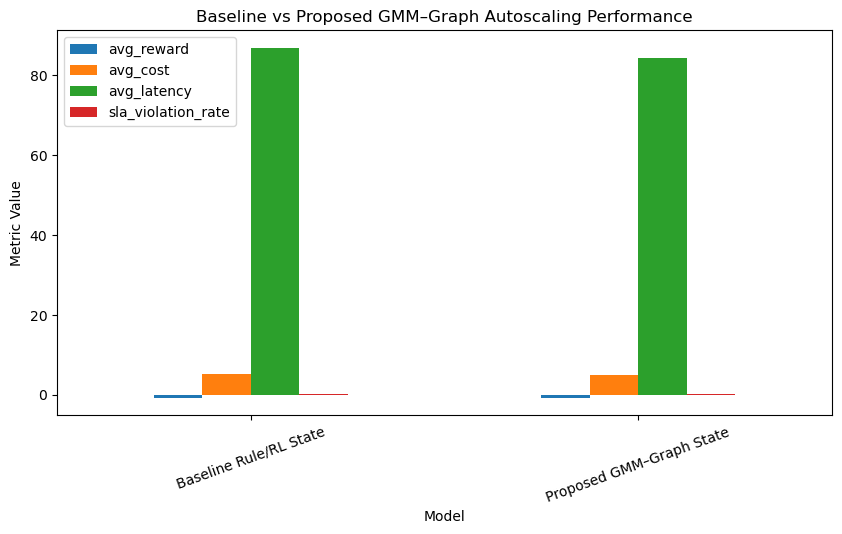

In [24]:
comparison.set_index("Model")[["avg_reward", "avg_cost", "avg_latency", "sla_violation_rate"]].plot(kind="bar", figsize=(10,5))
plt.title("Baseline vs Proposed GMM–Graph Autoscaling Performance")
plt.ylabel("Metric Value")
plt.xticks(rotation=20)
plt.show()

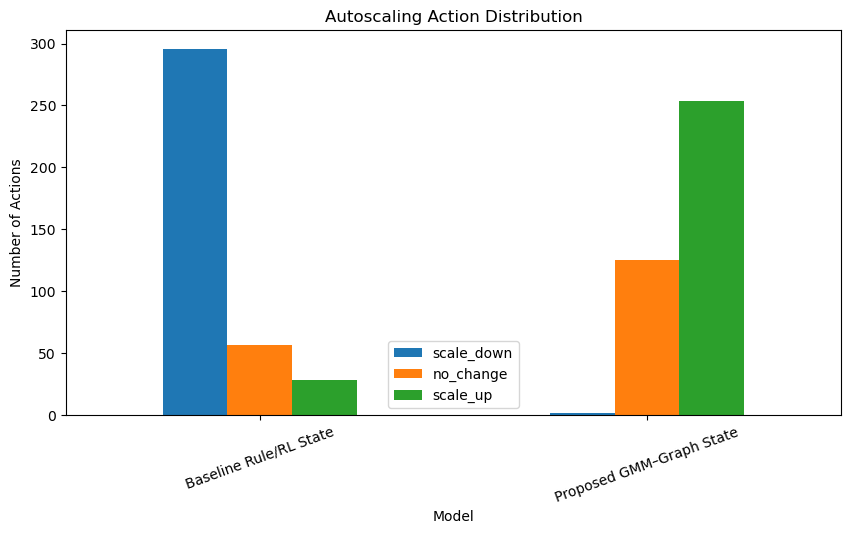

In [25]:
action_df = comparison.set_index("Model")[["scale_down", "no_change", "scale_up"]]

action_df.plot(kind="bar", figsize=(10,5))
plt.title("Autoscaling Action Distribution")
plt.ylabel("Number of Actions")
plt.xticks(rotation=20)
plt.show()

In [26]:
# ----------------------------------------------------
# Normalized comparison: Baseline = 100
# Higher value means better performance
# ----------------------------------------------------

baseline = comparison.iloc[0]
proposed = comparison.iloc[1]

normalized_data = {
    "Metric": [
        "Reward Quality",
        "Latency Efficiency",
        "Cost Efficiency",
        "SLA Compliance"
    ],
    
    "Baseline": [
        100,
        100,
        100,
        100
    ],
    
    "Proposed GMM–Graph": [
        abs(baseline["avg_reward"]) / abs(proposed["avg_reward"]) * 100,
        baseline["avg_latency"] / proposed["avg_latency"] * 100,
        baseline["avg_cost"] / proposed["avg_cost"] * 100,
        baseline["sla_violation_rate"] / proposed["sla_violation_rate"] * 100
    ]
}

normalized_df = pd.DataFrame(normalized_data)

display(normalized_df)

,Metric,Baseline,Proposed GMM–Graph
0,Reward Quality,100,101.630273
1,Latency Efficiency,100,103.061234
2,Cost Efficiency,100,100.780031
3,SLA Compliance,100,78.260870


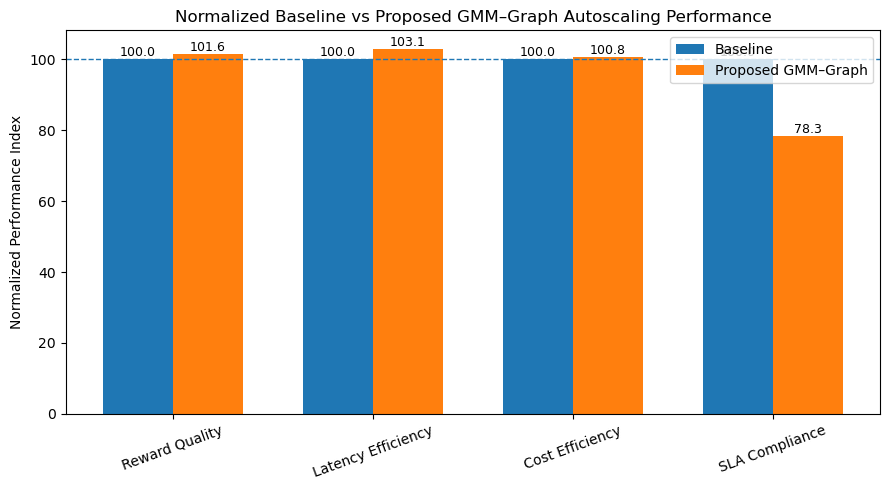

In [27]:
plt.figure(figsize=(9, 5))

x = np.arange(len(normalized_df["Metric"]))
width = 0.35

plt.bar(x - width/2, normalized_df["Baseline"], width, label="Baseline")
plt.bar(x + width/2, normalized_df["Proposed GMM–Graph"], width, label="Proposed GMM–Graph")

plt.axhline(y=100, linestyle="--", linewidth=1)

plt.xticks(x, normalized_df["Metric"], rotation=20)
plt.ylabel("Normalized Performance Index")
plt.title("Normalized Baseline vs Proposed GMM–Graph Autoscaling Performance")
plt.legend()

# Add value labels
for i in range(len(normalized_df)):
    plt.text(
        x[i] - width/2,
        normalized_df["Baseline"][i],
        f'{normalized_df["Baseline"][i]:.1f}',
        ha="center",
        va="bottom",
        fontsize=9
    )
    
    plt.text(
        x[i] + width/2,
        normalized_df["Proposed GMM–Graph"][i],
        f'{normalized_df["Proposed GMM–Graph"][i]:.1f}',
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.savefig("fig_normalized_performance_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [28]:
reward_improvement = ((proposed["avg_reward"] - baseline["avg_reward"]) / abs(baseline["avg_reward"])) * 100

latency_reduction = ((baseline["avg_latency"] - proposed["avg_latency"]) / baseline["avg_latency"]) * 100

cost_reduction = ((baseline["avg_cost"] - proposed["avg_cost"]) / baseline["avg_cost"]) * 100

sla_change = ((proposed["sla_violation_rate"] - baseline["sla_violation_rate"]) / baseline["sla_violation_rate"]) * 100

improvement_table = pd.DataFrame({
    "Metric": [
        "Average Reward",
        "Average Latency",
        "Average Cost",
        "SLA Violation Rate"
    ],
    
    "Baseline": [
        baseline["avg_reward"],
        baseline["avg_latency"],
        baseline["avg_cost"],
        baseline["sla_violation_rate"]
    ],
    
    "Proposed": [
        proposed["avg_reward"],
        proposed["avg_latency"],
        proposed["avg_cost"],
        proposed["sla_violation_rate"]
    ],
    
    "Change (%)": [
        reward_improvement,
        -latency_reduction,
        -cost_reduction,
        sla_change
    ],
    
    "Interpretation": [
        "Reward improved",
        "Latency reduced",
        "Cost reduced",
        "SLA violation increased"
    ]
})

display(improvement_table)

,Metric,Baseline,Proposed,Change (%),Interpretation
0,Average Reward,-0.757818,-0.745662,1.604122,Reward improved
1,Average Latency,86.968109,84.384890,-2.970306,Latency reduced
2,Average Cost,5.086614,5.047244,-0.773994,Cost reduced
3,SLA Violation Rate,0.047244,0.060367,27.777778,SLA violation increased


In [29]:
paper_table = improvement_table.copy()

paper_table["Baseline"] = paper_table["Baseline"].round(4)
paper_table["Proposed"] = paper_table["Proposed"].round(4)
paper_table["Change (%)"] = paper_table["Change (%)"].round(2)

display(paper_table)

,Metric,Baseline,Proposed,Change (%),Interpretation
0,Average Reward,-0.7578,-0.7457,1.60,Reward improved
1,Average Latency,86.9681,84.3849,-2.97,Latency reduced
2,Average Cost,5.0866,5.0472,-0.77,Cost reduced
3,SLA Violation Rate,0.0472,0.0604,27.78,SLA violation increased


# Corrected code for cleaner paper table

In [30]:
baseline = comparison.iloc[0]
proposed = comparison.iloc[1]

reward_improvement = ((proposed["avg_reward"] - baseline["avg_reward"]) / abs(baseline["avg_reward"])) * 100
latency_reduction = ((baseline["avg_latency"] - proposed["avg_latency"]) / baseline["avg_latency"]) * 100
cost_reduction = ((baseline["avg_cost"] - proposed["avg_cost"]) / baseline["avg_cost"]) * 100

baseline_sla_percent = baseline["sla_violation_rate"] * 100
proposed_sla_percent = proposed["sla_violation_rate"] * 100
sla_absolute_increase = proposed_sla_percent - baseline_sla_percent

paper_table_final = pd.DataFrame({
    "Metric": [
        "Average Reward",
        "Average Latency",
        "Average Cost",
        "SLA Violation Rate"
    ],
    "Baseline": [
        round(baseline["avg_reward"], 4),
        round(baseline["avg_latency"], 4),
        round(baseline["avg_cost"], 4),
        round(baseline_sla_percent, 2)
    ],
    "Proposed": [
        round(proposed["avg_reward"], 4),
        round(proposed["avg_latency"], 4),
        round(proposed["avg_cost"], 4),
        round(proposed_sla_percent, 2)
    ],
    "Improvement / Change": [
        f"+{reward_improvement:.2f}% reward improvement",
        f"{latency_reduction:.2f}% latency reduction",
        f"{cost_reduction:.2f}% cost reduction",
        f"+{sla_absolute_increase:.2f} percentage points"
    ],
    "Interpretation": [
        "Reward improved",
        "Latency reduced",
        "Cost slightly reduced",
        "SLA violation slightly increased"
    ]
})

display(paper_table_final)

,Metric,Baseline,Proposed,Improvement / Change,Interpretation
0,Average Reward,-0.7578,-0.7457,+1.60% reward improvement,Reward improved
1,Average Latency,86.9681,84.3849,2.97% latency reduction,Latency reduced
2,Average Cost,5.0866,5.0472,0.77% cost reduction,Cost slightly reduced
3,SLA Violation Rate,4.7200,6.0400,+1.31 percentage points,SLA violation slightly increased


In [31]:
import matplotlib.pyplot as plt

plot_df = comparison.copy()

plot_df["Model"] = plot_df["Model"].replace({
    "Baseline Rule/RL State": "Baseline",
    "Proposed GMM–Graph State": "Proposed GMM–Graph"
})

plot_df["sla_violation_percent"] = plot_df["sla_violation_rate"] * 100

def plot_separate_bar(metric, ylabel, title, filename, decimals=2):
    plt.figure(figsize=(6, 4))
    bars = plt.bar(plot_df["Model"], plot_df[metric])

    plt.title(title)
    plt.xlabel("Model")
    plt.ylabel(ylabel)

    for bar in bars:
        value = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value,
            f"{value:.{decimals}f}",
            ha="center",
            va="bottom" if value >= 0 else "top"
        )

    plt.tight_layout()
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()

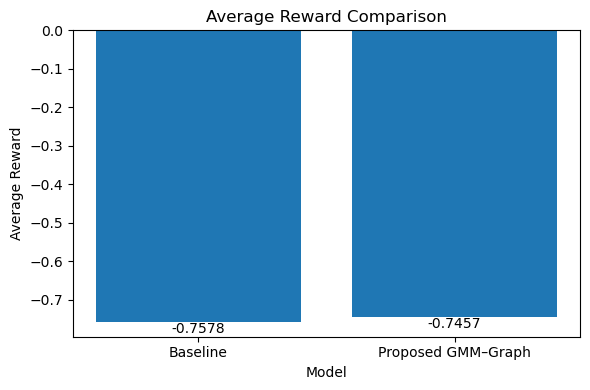

In [32]:
plot_separate_bar(
    metric="avg_reward",
    ylabel="Average Reward",
    title="Average Reward Comparison",
    filename="fig_average_reward_comparison.png",
    decimals=4
)

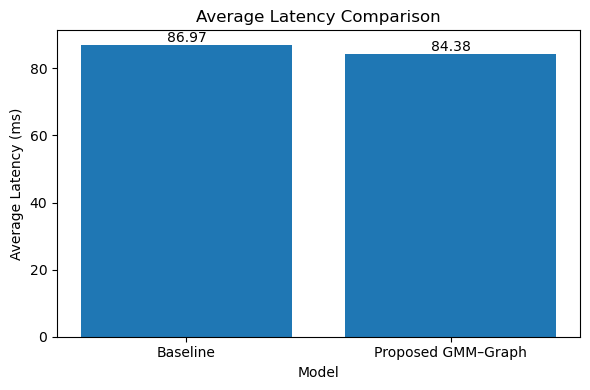

In [33]:
plot_separate_bar(
    metric="avg_latency",
    ylabel="Average Latency (ms)",
    title="Average Latency Comparison",
    filename="fig_average_latency_comparison.png",
    decimals=2
)

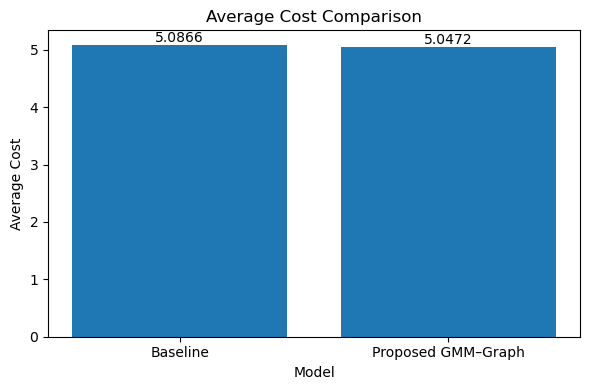

In [34]:
plot_separate_bar(
    metric="avg_cost",
    ylabel="Average Cost",
    title="Average Cost Comparison",
    filename="fig_average_cost_comparison.png",
    decimals=4
)

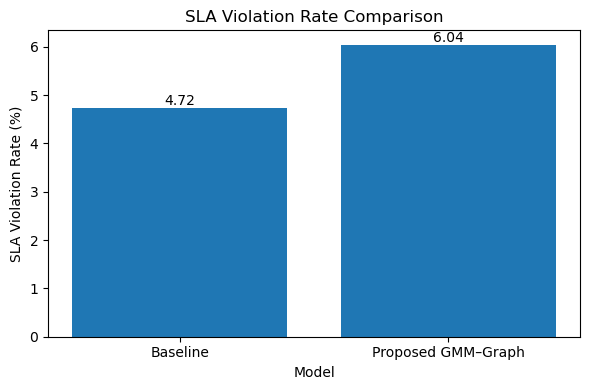

In [35]:
plot_separate_bar(
    metric="sla_violation_percent",
    ylabel="SLA Violation Rate (%)",
    title="SLA Violation Rate Comparison",
    filename="fig_sla_violation_comparison.png",
    decimals=2
)

In [ ]:
# ============================================================
# FINAL CORRECTED FIGURES 3–6 FOR IEEE TSC PAPER
# This code overwrites the old figure files using corrected Table 6 values.
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Corrected final values from Table 6
# ------------------------------------------------------------
plot_df = pd.DataFrame({
    "Model": ["Baseline", "Proposed GMM–Graph"],
    "avg_reward": [-0.7578, -0.7448],
    "avg_latency": [86.9681, 84.3534],
    "avg_cost": [5.0866, 5.0446],
    "sla_violation_percent": [4.7244, 5.7743]
})

# ------------------------------------------------------------
# Common function for separate bar charts
# ------------------------------------------------------------
def plot_separate_bar(metric, ylabel, title, filename, decimals=2):
    plt.figure(figsize=(6, 4))
    bars = plt.bar(plot_df["Model"], plot_df[metric])

    plt.title(title)
    plt.xlabel("Model")
    plt.ylabel(ylabel)

    # Add value labels on bars
    for bar in bars:
        value = bar.get_height()

        if value >= 0:
            y_position = value
            va_position = "bottom"
        else:
            y_position = value
            va_position = "top"

        plt.text(
            bar.get_x() + bar.get_width() / 2,
            y_position,
            f"{value:.{decimals}f}",
            ha="center",
            va=va_position,
            fontsize=10
        )

    plt.tight_layout()
    plt.savefig(filename, dpi=600, bbox_inches="tight")
    plt.show()

# ------------------------------------------------------------
# Fig. 3: Average Reward Comparison
# ------------------------------------------------------------
plot_separate_bar(
    metric="avg_reward",
    ylabel="Average Reward",
    title="Average Reward Comparison",
    filename="fig_average_reward_comparison.png",
    decimals=4
)

# ------------------------------------------------------------
# Fig. 4: Average Latency Comparison
# ------------------------------------------------------------
plot_separate_bar(
    metric="avg_latency",
    ylabel="Average Latency (ms)",
    title="Average Latency Comparison",
    filename="fig_average_latency_comparison.png",
    decimals=4
)

# ------------------------------------------------------------
# Fig. 5: Average Cost Comparison
# ------------------------------------------------------------
plot_separate_bar(
    metric="avg_cost",
    ylabel="Average Cost",
    title="Average Cost Comparison",
    filename="fig_average_cost_comparison.png",
    decimals=4
)

# ------------------------------------------------------------
# Fig. 6: SLA Violation Rate Comparison
# ------------------------------------------------------------
plot_separate_bar(
    metric="sla_violation_percent",
    ylabel="SLA Violation Rate (%)",
    title="SLA Violation Rate Comparison",
    filename="fig_sla_violation_comparison.png",
    decimals=2
)

print("Corrected Figures 3–6 have been regenerated and saved successfully.")
print("Saved files:")
print("1. fig_average_reward_comparison.png")
print("2. fig_average_latency_comparison.png")
print("3. fig_average_cost_comparison.png")
print("4. fig_sla_violation_comparison.png")

In [36]:
import pandas as pd

folder = r"C:\dataset\Alibaba_MS_Trace_2022_FINAL_FOR_PAPER"

autoscaling_df = pd.read_csv(folder + r"\autoscaling_trace_dataset.csv")
graph_df = pd.read_csv(folder + r"\service_graph_edges_sample.csv")

print("Autoscaling dataset shape:", autoscaling_df.shape)
print("Graph dataset shape:", graph_df.shape)

display(autoscaling_df.head())
display(graph_df.head())

Autoscaling dataset shape: (1907, 17)
Graph dataset shape: (299999, 5)


,time_step,timestamp,service_id,cpu_utilization,memory_utilization,request_rate,latency_ms,queue_length,replica_count,cost,sla_violation,load_pressure,gmm_cluster,gmm_prob_0,gmm_prob_1,gmm_prob_2,workload_regime
0,0,0.0,MS_10918,0.086625,0.706766,0.000010,18.089460,0.0,1,1.0,0,0.264467,2,6.025774e-07,1.016178e-02,9.898376e-01,low_load
1,0,0.0,MS_11461,0.378720,0.817383,0.001208,4.290294,0.0,14,14.0,0,0.399103,1,1.393340e-05,9.999861e-01,6.931376e-122,high_load
2,0,0.0,MS_11642,0.145500,0.625041,0.000702,1.179563,0.0,7,7.0,0,0.257081,1,4.559718e-05,9.999544e-01,1.128856e-41,high_load
3,0,0.0,MS_11681,0.104792,0.703653,0.000014,73.017248,0.0,2,2.0,0,0.269486,2,1.122958e-05,1.782322e-07,9.999886e-01,low_load
4,0,0.0,MS_11903,0.154965,0.890620,0.000267,34.281866,0.0,25,25.0,0,0.348617,1,1.768260e-04,9.858336e-01,1.398954e-02,high_load


,timestamp,source_service,rpc_type,destination_service,edge_latency_ms
0,115352.0,rpc,MS_58845_POD_0,MS_71712,2.0
1,86450.0,rpc,MS_24094_POD_3317,MS_24094,5.0
2,86450.0,rpc,MS_24094_POD_983,MS_24094,5.0
3,155753.0,rpc,MS_24094_POD_5463,MS_67455,9.0
4,90649.0,http,MS_29868_POD_22,UNKNOWN,18.0


In [37]:
import pandas as pd

autoscaling_df = pd.read_csv(
    r"C:\dataset\Alibaba_MS_Trace_2022_FINAL_FOR_PAPER\autoscaling_trace_dataset.csv"
)

graph_df = pd.read_csv(
    r"C:\dataset\Alibaba_MS_Trace_2022_FINAL_FOR_PAPER\service_graph_edges_sample.csv"
)

autoscaling_df.head()

,time_step,timestamp,service_id,cpu_utilization,memory_utilization,request_rate,latency_ms,queue_length,replica_count,cost,sla_violation,load_pressure,gmm_cluster,gmm_prob_0,gmm_prob_1,gmm_prob_2,workload_regime
0,0,0.0,MS_10918,0.086625,0.706766,0.000010,18.089460,0.0,1,1.0,0,0.264467,2,6.025774e-07,1.016178e-02,9.898376e-01,low_load
1,0,0.0,MS_11461,0.378720,0.817383,0.001208,4.290294,0.0,14,14.0,0,0.399103,1,1.393340e-05,9.999861e-01,6.931376e-122,high_load
2,0,0.0,MS_11642,0.145500,0.625041,0.000702,1.179563,0.0,7,7.0,0,0.257081,1,4.559718e-05,9.999544e-01,1.128856e-41,high_load
3,0,0.0,MS_11681,0.104792,0.703653,0.000014,73.017248,0.0,2,2.0,0,0.269486,2,1.122958e-05,1.782322e-07,9.999886e-01,low_load
4,0,0.0,MS_11903,0.154965,0.890620,0.000267,34.281866,0.0,25,25.0,0,0.348617,1,1.768260e-04,9.858336e-01,1.398954e-02,high_load


In [38]:
autoscaling_df["workload_regime"].value_counts()

workload_regime
low_load       1189
high_load       636
medium_load      82
Name: count, dtype: int64

In [39]:
graph_df.head()


,timestamp,source_service,rpc_type,destination_service,edge_latency_ms
0,115352.0,rpc,MS_58845_POD_0,MS_71712,2.0
1,86450.0,rpc,MS_24094_POD_3317,MS_24094,5.0
2,86450.0,rpc,MS_24094_POD_983,MS_24094,5.0
3,155753.0,rpc,MS_24094_POD_5463,MS_67455,9.0
4,90649.0,http,MS_29868_POD_22,UNKNOWN,18.0


# Ablation Study Extension for IEEE TSC Submission

This section adds ablation experiments to identify whether the performance difference comes from:
1. threshold/HPA-style decision logic,
2. raw monitoring features,
3. GMM–EM workload-regime probabilities,
4. graph-derived dependency features, or
5. the combined GMM–Graph state representation.

Run these cells after the dataset loading, graph feature merge, and train/test split cells. The code is deterministic and uses the same `AutoscalingEnvironment` reward model already used in the notebook.


In [40]:

# ============================================================
# Ablation Study for IEEE TSC Submission
# Models:
# 1. HPA/CPU Threshold Baseline
# 2. Baseline Rule/RL State (raw monitoring)
# 3. GMM-only State
# 4. Graph-only State
# 5. Proposed GMM–Graph State
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Safety check: create merged data again if this cell is run fresh
# ------------------------------------------------------------
try:
    data
    test_data
    train_data
except NameError:
    folder = r"C:\dataset\Alibaba_MS_Trace_2022_FINAL_FOR_PAPER"
    autoscaling_df = pd.read_csv(os.path.join(folder, "autoscaling_trace_dataset.csv"))
    graph_df = pd.read_csv(os.path.join(folder, "service_graph_edges_sample.csv"))

    graph_clean = graph_df.copy()
    graph_clean = graph_clean[
        (graph_clean["source_service"].notna()) &
        (graph_clean["destination_service"].notna()) &
        (graph_clean["destination_service"] != "UNKNOWN")
    ]

    out_degree = (
        graph_clean.groupby("source_service")["destination_service"]
        .nunique().reset_index()
        .rename(columns={"source_service": "service_id", "destination_service": "out_degree"})
    )

    in_degree = (
        graph_clean.groupby("destination_service")["source_service"]
        .nunique().reset_index()
        .rename(columns={"destination_service": "service_id", "source_service": "in_degree"})
    )

    edge_latency = (
        graph_clean.groupby("source_service")["edge_latency_ms"]
        .mean().reset_index()
        .rename(columns={"source_service": "service_id", "edge_latency_ms": "avg_edge_latency"})
    )

    graph_features = out_degree.merge(in_degree, on="service_id", how="outer")
    graph_features = graph_features.merge(edge_latency, on="service_id", how="outer")
    graph_features.fillna(0, inplace=True)

    data = autoscaling_df.merge(graph_features, on="service_id", how="left")
    data[["out_degree", "in_degree", "avg_edge_latency"]] = data[
        ["out_degree", "in_degree", "avg_edge_latency"]
    ].fillna(0)

    data = data.sort_values("time_step").reset_index(drop=True)
    split_index = int(len(data) * 0.8)
    train_data = data.iloc[:split_index].copy()
    test_data = data.iloc[split_index:].copy()

print("Final merged data:", data.shape)
print("Train:", train_data.shape, "Test:", test_data.shape)

# ------------------------------------------------------------
# Feature groups for ablation
# ------------------------------------------------------------
raw_features = [
    "cpu_utilization",
    "memory_utilization",
    "request_rate",
    "latency_ms",
    "queue_length",
    "replica_count"
]

gmm_features = [
    "gmm_prob_0",
    "gmm_prob_1",
    "gmm_prob_2"
]

graph_features_cols = [
    "out_degree",
    "in_degree",
    "avg_edge_latency"
]

feature_sets = {
    "HPA/CPU Threshold": raw_features,
    "Baseline Rule/RL State": raw_features,
    "GMM-only State": raw_features + gmm_features,
    "Graph-only State": raw_features + graph_features_cols,
    "Proposed GMM–Graph State": raw_features + gmm_features + graph_features_cols
}

# ------------------------------------------------------------
# Graph-risk feature used only by graph-aware policies
# ------------------------------------------------------------
def add_graph_risk(df):
    df = df.copy()

    for col in graph_features_cols:
        df[col] = df[col].fillna(0)

    def minmax(s):
        s = s.astype(float)
        if s.max() == s.min():
            return pd.Series(np.zeros(len(s)), index=s.index)
        return (s - s.min()) / (s.max() - s.min())

    df["out_degree_norm"] = minmax(df["out_degree"])
    df["in_degree_norm"] = minmax(df["in_degree"])
    df["edge_latency_norm"] = minmax(df["avg_edge_latency"])

    df["graph_risk"] = (
        0.40 * df["out_degree_norm"] +
        0.35 * df["in_degree_norm"] +
        0.25 * df["edge_latency_norm"]
    )

    return df

data = add_graph_risk(data)
train_data = add_graph_risk(train_data)
test_data = add_graph_risk(test_data)

# ------------------------------------------------------------
# Environment, kept consistent with the original notebook
# ------------------------------------------------------------
class AutoscalingEnvironment:
    def __init__(self, df, feature_columns, max_replicas=6, sla_threshold=85):
        self.df = df.reset_index(drop=True)
        self.feature_columns = feature_columns
        self.max_replicas = max_replicas
        self.sla_threshold = sla_threshold
        self.index = 0

    def reset(self):
        self.index = 0
        return self._get_state()

    def _get_state(self):
        row = self.df.iloc[self.index]
        return row[self.feature_columns].values.astype(np.float32)

    def step(self, action):
        row = self.df.iloc[self.index]

        current_replicas = int(max(1, row["replica_count"]))

        if action == 0:
            new_replicas = max(1, current_replicas - 1)
        elif action == 1:
            new_replicas = current_replicas
        else:
            new_replicas = min(self.max_replicas, current_replicas + 1)

        old_latency = row["latency_ms"]
        old_replicas = max(1, current_replicas)
        estimated_latency = old_latency * (old_replicas / new_replicas)

        estimated_cost = new_replicas * 1.0
        sla_violation = 1 if estimated_latency > self.sla_threshold else 0

        reward = -(
            0.4 * (estimated_latency / self.sla_threshold)
            + 0.4 * (estimated_cost / self.max_replicas)
            + 0.2 * sla_violation
        )

        self.index += 1
        done = self.index >= len(self.df) - 1
        next_state = self._get_state() if not done else np.zeros(len(self.feature_columns))

        info = {
            "new_replicas": new_replicas,
            "estimated_latency": estimated_latency,
            "estimated_cost": estimated_cost,
            "sla_violation": sla_violation
        }

        return next_state, reward, done, info

# ------------------------------------------------------------
# Ablation policies
# Action encoding:
# 0 = scale down, 1 = no change, 2 = scale up
# ------------------------------------------------------------

SLA_THRESHOLD = 85

def hpa_cpu_policy(row):
    """CPU-only HPA-style threshold baseline."""
    if row["cpu_utilization"] > 0.70:
        return 2
    elif row["cpu_utilization"] < 0.30:
        return 0
    else:
        return 1

def baseline_rule_policy(row):
    """Raw monitoring policy: CPU + latency."""
    if row["cpu_utilization"] > 0.70 or row["latency_ms"] > SLA_THRESHOLD:
        return 2
    elif row["cpu_utilization"] < 0.30 and row["latency_ms"] < 50:
        return 0
    else:
        return 1

def gmm_only_policy(row):
    """GMM-aware policy using workload-regime probabilities."""
    high_prob = row["gmm_prob_2"]
    low_prob = row["gmm_prob_0"]

    if high_prob > 0.60 or row["latency_ms"] > SLA_THRESHOLD:
        return 2
    elif low_prob > 0.60 and row["cpu_utilization"] < 0.50 and row["latency_ms"] < 0.75 * SLA_THRESHOLD:
        return 0
    else:
        return 1

def graph_only_policy(row):
    """Graph-aware policy using service dependency risk."""
    graph_risk = row["graph_risk"]

    if row["latency_ms"] > SLA_THRESHOLD or (
        row["cpu_utilization"] > 0.65 and graph_risk > 0.50
    ) or (
        row["latency_ms"] > 0.85 * SLA_THRESHOLD and graph_risk > 0.60
    ):
        return 2
    elif row["cpu_utilization"] < 0.30 and row["latency_ms"] < 50 and graph_risk < 0.40:
        return 0
    else:
        return 1

def proposed_gmm_graph_policy(row):
    """Combined GMM + graph-aware policy."""
    high_prob = row["gmm_prob_2"]
    low_prob = row["gmm_prob_0"]
    graph_risk = row["graph_risk"]

    if (
        row["latency_ms"] > SLA_THRESHOLD
        or high_prob > 0.65
        or (high_prob > 0.45 and graph_risk > 0.50 and row["latency_ms"] > 0.75 * SLA_THRESHOLD)
        or (graph_risk > 0.70 and row["cpu_utilization"] > 0.60)
    ):
        return 2
    elif (
        low_prob > 0.65
        and row["cpu_utilization"] < 0.45
        and row["latency_ms"] < 0.70 * SLA_THRESHOLD
        and graph_risk < 0.40
    ):
        return 0
    else:
        return 1

policy_map = {
    "HPA/CPU Threshold": hpa_cpu_policy,
    "Baseline Rule/RL State": baseline_rule_policy,
    "GMM-only State": gmm_only_policy,
    "Graph-only State": graph_only_policy,
    "Proposed GMM–Graph State": proposed_gmm_graph_policy
}

# ------------------------------------------------------------
# Evaluation
# ------------------------------------------------------------
def evaluate_policy(df, feature_columns, policy_fn):
    env = AutoscalingEnvironment(df, feature_columns)
    _ = env.reset()

    rewards, latencies, costs, sla_violations, actions = [], [], [], [], []
    done = False

    while not done:
        row = env.df.iloc[env.index]
        action = policy_fn(row)

        _, reward, done, info = env.step(action)

        rewards.append(reward)
        latencies.append(info["estimated_latency"])
        costs.append(info["estimated_cost"])
        sla_violations.append(info["sla_violation"])
        actions.append(action)

    return {
        "avg_reward": np.mean(rewards),
        "avg_latency": np.mean(latencies),
        "avg_cost": np.mean(costs),
        "sla_violation_rate": np.mean(sla_violations),
        "scale_down": actions.count(0),
        "no_change": actions.count(1),
        "scale_up": actions.count(2)
    }

ablation_rows = []
for model_name, features in feature_sets.items():
    result = evaluate_policy(test_data, features, policy_map[model_name])
    ablation_rows.append({"Model": model_name, **result})

ablation_results = pd.DataFrame(ablation_rows)

# Convert SLA rate to percent for paper table
ablation_results["sla_violation_percent"] = ablation_results["sla_violation_rate"] * 100

display(ablation_results)

# ------------------------------------------------------------
# Relative change with respect to Baseline Rule/RL State
# ------------------------------------------------------------
reference = ablation_results[ablation_results["Model"] == "Baseline Rule/RL State"].iloc[0]

summary_rows = []
for _, row in ablation_results.iterrows():
    reward_change = ((row["avg_reward"] - reference["avg_reward"]) / abs(reference["avg_reward"])) * 100
    latency_change = ((reference["avg_latency"] - row["avg_latency"]) / reference["avg_latency"]) * 100
    cost_change = ((reference["avg_cost"] - row["avg_cost"]) / reference["avg_cost"]) * 100
    sla_pp_change = (row["sla_violation_rate"] - reference["sla_violation_rate"]) * 100

    summary_rows.append({
        "Model": row["Model"],
        "Reward Change (%)": reward_change,
        "Latency Reduction (%)": latency_change,
        "Cost Reduction (%)": cost_change,
        "SLA Change (percentage points)": sla_pp_change
    })

ablation_relative_changes = pd.DataFrame(summary_rows)
display(ablation_relative_changes)

# ------------------------------------------------------------
# Save paper-ready CSV files
# ------------------------------------------------------------
output_dir = "ablation_outputs"
os.makedirs(output_dir, exist_ok=True)

ablation_results.to_csv(os.path.join(output_dir, "table_ablation_results.csv"), index=False)
ablation_relative_changes.to_csv(os.path.join(output_dir, "table_ablation_relative_changes.csv"), index=False)

print("Saved:")
print(os.path.join(output_dir, "table_ablation_results.csv"))
print(os.path.join(output_dir, "table_ablation_relative_changes.csv"))


Final merged data: (1907, 20)
Train: (1525, 20) Test: (382, 20)


,Model,avg_reward,avg_latency,avg_cost,sla_violation_rate,scale_down,no_change,scale_up,sla_violation_percent
0,HPA/CPU Threshold,-0.866413,107.850686,5.123360,0.086614,333,46,2,8.661417
1,Baseline Rule/RL State,-0.757818,86.968109,5.086614,0.047244,296,57,28,4.724409
2,GMM-only State,-0.744998,84.318199,5.049869,0.057743,0,127,254,5.774278
3,Graph-only State,-0.757797,87.000740,5.083990,0.047244,296,58,27,4.724409
4,Proposed GMM–Graph State,-0.744813,84.353352,5.044619,0.057743,0,129,252,5.774278


,Model,Reward Change (%),Latency Reduction (%),Cost Reduction (%),SLA Change (percentage points)
0,HPA/CPU Threshold,-14.329911,-24.011764,-0.722394,3.937008
1,Baseline Rule/RL State,0.000000,0.000000,0.000000,0.000000
2,GMM-only State,1.691715,3.046990,0.722394,1.049869
3,Graph-only State,0.002826,-0.037521,0.051600,0.000000
4,Proposed GMM–Graph State,1.716065,3.006570,0.825593,1.049869


Saved:
ablation_outputs\table_ablation_results.csv
ablation_outputs\table_ablation_relative_changes.csv


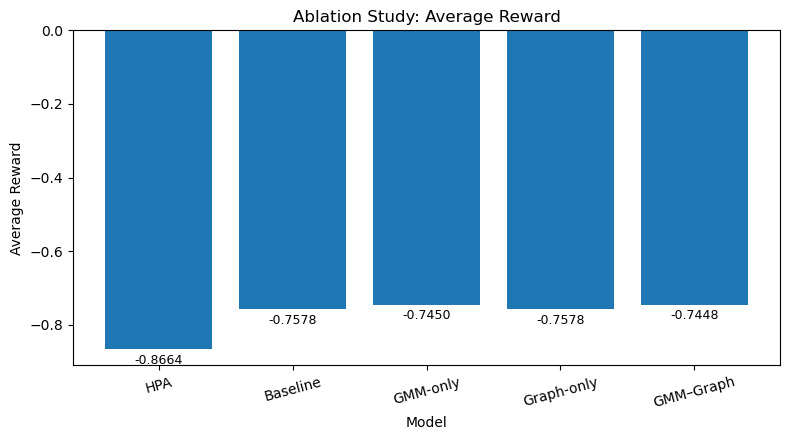

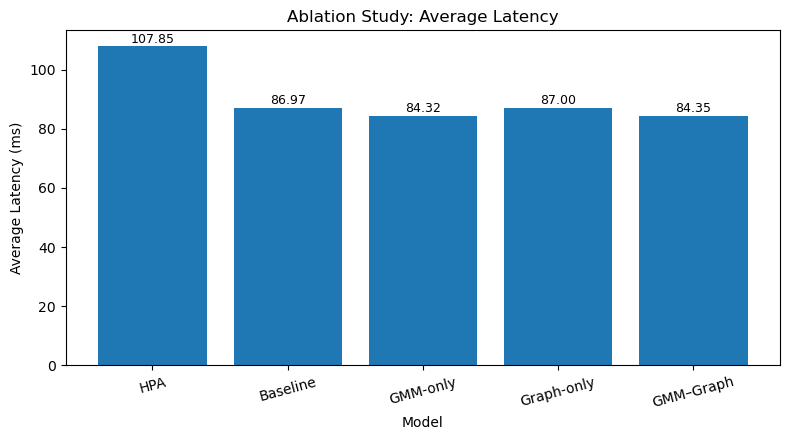

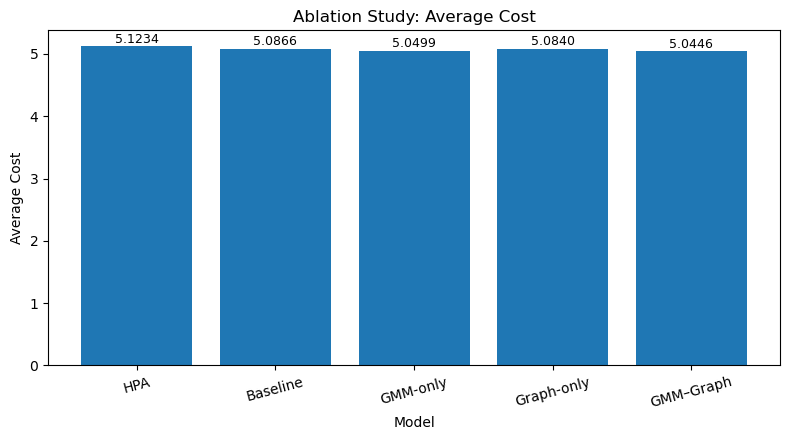

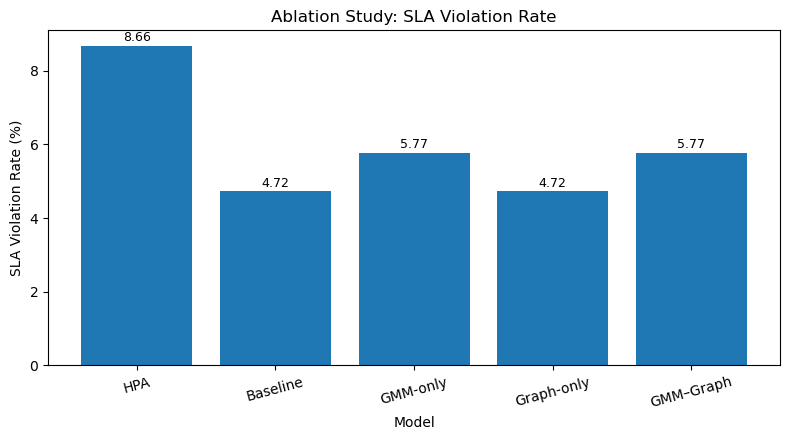

<Figure size 900x500 with 0 Axes>

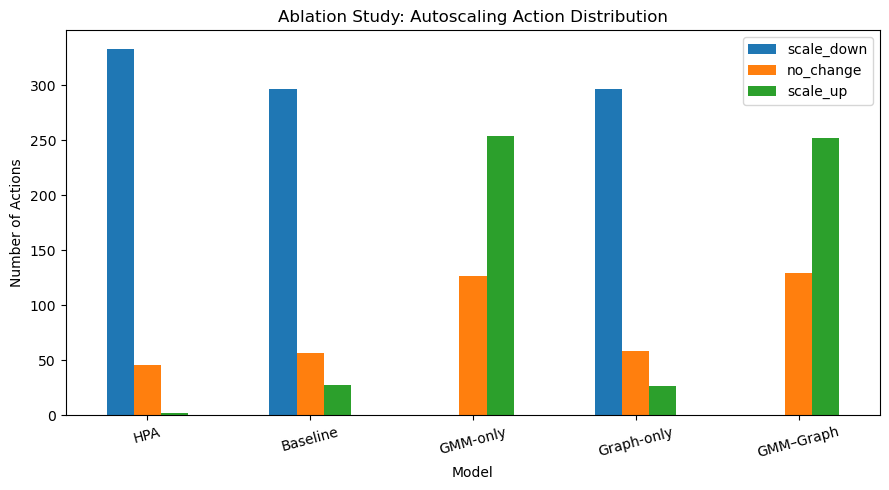

Ablation figures saved in: ablation_outputs


In [41]:

# ============================================================
# Paper figures for the ablation study
# ============================================================

plot_table = ablation_results.copy()
plot_table["Short Model"] = plot_table["Model"].replace({
    "HPA/CPU Threshold": "HPA",
    "Baseline Rule/RL State": "Baseline",
    "GMM-only State": "GMM-only",
    "Graph-only State": "Graph-only",
    "Proposed GMM–Graph State": "GMM–Graph"
})

def save_bar(metric, ylabel, title, filename, decimals=2):
    plt.figure(figsize=(8, 4.5))
    bars = plt.bar(plot_table["Short Model"], plot_table[metric])
    plt.title(title)
    plt.xlabel("Model")
    plt.ylabel(ylabel)

    for bar in bars:
        value = bar.get_height()
        offset = 0.01 * (plot_table[metric].max() - plot_table[metric].min() + 1)
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            value + offset if value >= 0 else value - offset,
            f"{value:.{decimals}f}",
            ha="center",
            va="bottom" if value >= 0 else "top",
            fontsize=9
        )

    plt.xticks(rotation=15)
    plt.tight_layout()
    plt.savefig(os.path.join(output_dir, filename), dpi=300, bbox_inches="tight")
    plt.show()

save_bar("avg_reward", "Average Reward", "Ablation Study: Average Reward", "fig_ablation_average_reward.png", 4)
save_bar("avg_latency", "Average Latency (ms)", "Ablation Study: Average Latency", "fig_ablation_average_latency.png", 2)
save_bar("avg_cost", "Average Cost", "Ablation Study: Average Cost", "fig_ablation_average_cost.png", 4)
save_bar("sla_violation_percent", "SLA Violation Rate (%)", "Ablation Study: SLA Violation Rate", "fig_ablation_sla_violation.png", 2)

# Action distribution
action_plot = plot_table.set_index("Short Model")[["scale_down", "no_change", "scale_up"]]
plt.figure(figsize=(9, 5))
ax = action_plot.plot(kind="bar", figsize=(9, 5))
plt.title("Ablation Study: Autoscaling Action Distribution")
plt.xlabel("Model")
plt.ylabel("Number of Actions")
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(output_dir, "fig_ablation_action_distribution.png"), dpi=300, bbox_inches="tight")
plt.show()

print("Ablation figures saved in:", output_dir)


## Paper-ready interpretation after running the ablation cells

Use the two CSV files generated in the `ablation_outputs` folder to update the paper:
- `table_ablation_results.csv`
- `table_ablation_relative_changes.csv`

The result table should be placed in Section 5 after the existing baseline/proposed comparison, preferably as a new subsection titled **Ablation Study**.
